# Notebook 05: Inference & Benchmark Comparison

In this final notebook, we put our trained model to the test!

### What we will do:
1. **Load Your Trained Model** from `checkpoints/best_colorizer.pth`.
2. **Load the Reference Model** (Zhang et al. ECCV 2016 from `colorization/`).
3. **Colorize Real Black & White Photos** (including historical Ansel Adams photos from `colorization/imgs/`).
4. **Side-by-Side Comparison:** Compare **Input Grayscale vs Your Custom Model vs Zhang ECCV16**!

### 1. Import Libraries & Set Up Paths

In [5]:
import os
import sys
# Add project root to sys.path so we can import from src and colorization
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.join("..", "colorization"))

import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from skimage import color
import torch.nn.functional as F

# Import our custom architecture and lab converter
from src.model import ResNetColorizationNet
from src.dataset import lab_to_rgb
import colorizers

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 2. Load Both Models (Your Model & Reference Model)

In [6]:
# 1. Load Your Custom Model
my_model = ResNetColorizationNet(pretrained=False).to(device)
checkpoint_path = os.path.join("..", "checkpoints", "best_colorizer.pth")

if os.path.exists(checkpoint_path):
    ckpt = torch.load(checkpoint_path, map_location=device)
    my_model.load_state_dict(ckpt["model_state_dict"])
    print(f"Successfully loaded your model from epoch {ckpt['epoch']} (Val Loss: {ckpt['val_loss']:.4f})!")
else:
    print("WARNING: Checkpoint not found. Train your model first in 04_training.ipynb!")
my_model.eval()

# 2. Load Zhang ECCV16 Reference Model
ref_eccv16 = colorizers.eccv16(pretrained=True).eval().to(device)
print("Successfully loaded Zhang ECCV16 reference model!")

C:\Users\parth\AppData\Local\Temp\ipykernel_21476\474477267.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(checkpoint_path, map_location=device)


Successfully loaded your model from epoch 24 (Val Loss: 0.0657)!
Successfully loaded Zhang ECCV16 reference model!


### 3. Inference Function for Any Arbitrary Image

In [7]:
def colorize_image(img_path):
    """
    Runs both your custom model and the Zhang ECCV16 model on an image.
    Returns (gray_img, my_colorized_rgb, ref_colorized_rgb, orig_rgb_if_available)
    """
    # Load image and resize to 256x256
    img_pil = Image.open(img_path).convert("RGB").resize((256, 256))
    img_np = np.array(img_pil)
    
    # Convert to Lab
    img_lab = color.rgb2lab(img_np).astype(np.float32)
    L_orig = img_lab[:, :, 0]
    
    # Normalize L to [-1, 1] for our model
    L_norm = (L_orig / 50.0) - 1.0
    L_tensor = torch.from_numpy(L_norm).unsqueeze(0).unsqueeze(0).to(device)  # (1, 1, 256, 256)
    
    # 1. Predict with our model
    with torch.no_grad():
        pred_ab = my_model(L_tensor).squeeze(0)  # (2, 256, 256)
    my_rgb = lab_to_rgb(L_tensor.squeeze(0), pred_ab)
    
    # 2. Predict with Zhang ECCV16 model
    # Zhang model expects L in [0, 100] with shape (1, 1, H, W)
    tens_l_orig = torch.Tensor(L_orig)[None, None, :, :].to(device)
    with torch.no_grad():
        eccv_out = ref_eccv16(tens_l_orig).cpu()
    # Postprocess tensor for ECCV16
    ref_lab = np.zeros((256, 256, 3))
    ref_lab[:, :, 0] = L_orig
    ref_lab[:, :, 1:] = eccv_out[0].numpy().transpose(1, 2, 0)
    ref_rgb = np.clip(color.lab2rgb(ref_lab), 0.0, 1.0)
    
    return img_pil.convert("L"), my_rgb, ref_rgb, img_pil

### 4. Test on Real Historical Photos (Ansel Adams Landscapes)

C:\Users\parth\AppData\Local\Temp\ipykernel_21476\1678342310.py:32: UserWarning: Conversion from CIE-LAB, via XYZ to sRGB color space resulted in 4 negative Z values that have been clipped to zero
  ref_rgb = np.clip(color.lab2rgb(ref_lab), 0.0, 1.0)
C:\Users\parth\AppData\Local\Temp\ipykernel_21476\1621100104.py:30: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\parth\AppData\Local\Temp\ipykernel_21476\1621100104.py:32: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.savefig(save_path, dpi=200)


Saved benchmark comparison to ..\outputs\benchmark_comparison.png!


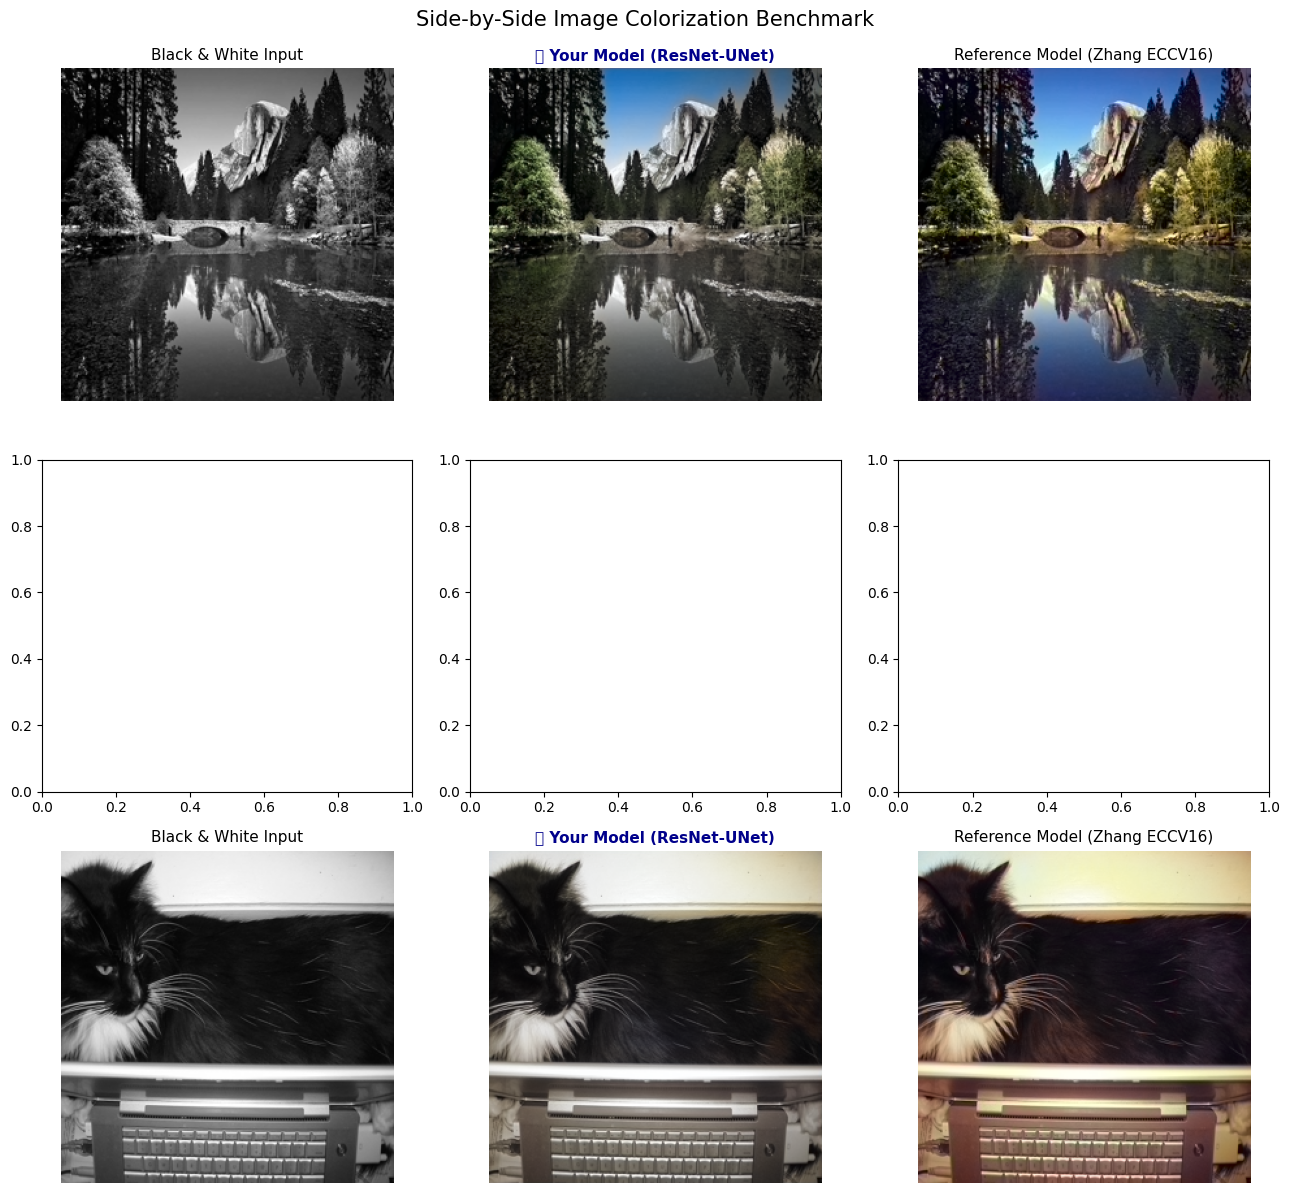

In [8]:
# Real B&W photos from the reference imgs folder
test_images = [
    os.path.join("..", "colorization", "imgs", "ansel_adams3.jpg"),
    os.path.join("..", "colorization", "imgs", "nature.jpg"),
    os.path.join("..", "data", "raw", "val", os.listdir(os.path.join("..", "data", "raw", "val"))[0])
]

fig, axes = plt.subplots(len(test_images), 3, figsize=(13, 4 * len(test_images)))

for row, p in enumerate(test_images):
    if os.path.exists(p):
        gray, my_out, ref_out, _ = colorize_image(p)
        
        # Col 1: Grayscale Input
        axes[row, 0].imshow(gray, cmap="gray")
        axes[row, 0].set_title("Black & White Input", fontsize=11)
        axes[row, 0].axis("off")
        
        # Col 2: Your Model
        axes[row, 1].imshow(my_out)
        axes[row, 1].set_title("⭐ Your Model (ResNet-UNet)", fontsize=11, color="darkblue", fontweight="bold")
        axes[row, 1].axis("off")
        
        # Col 3: Zhang ECCV16 Reference
        axes[row, 2].imshow(ref_out)
        axes[row, 2].set_title("Reference Model (Zhang ECCV16)", fontsize=11)
        axes[row, 2].axis("off")

plt.suptitle("Side-by-Side Image Colorization Benchmark", fontsize=15, y=0.99)
plt.tight_layout()
save_path = os.path.join("..", "outputs", "benchmark_comparison.png")
plt.savefig(save_path, dpi=200)
print(f"Saved benchmark comparison to {save_path}!")
plt.show()

### Congratulations! 🎉
You have completed your **Image Colorization Deep Learning Project**:
1. Explored CIE Lab color space (`01_data_exploration.ipynb`).
2. Built an augmented PyTorch dataset pipeline (`02_dataset_and_dataloader.ipynb`).
3. Designed a U-Net with ResNet-18 feature extraction (`03_model_architecture.ipynb`).
4. Accelerated training with GPU mixed precision (`04_training.ipynb`).
5. Benchmarked against the state-of-the-art reference model (`05_inference_and_benchmark.ipynb`)!